<div style="background:#FAF7F0; padding:18px 22px; border-left:7px solid #174D38; border-radius:10px; margin:16px 0;">

<h1 style="color:#174D38; margin:0 0 8px 0;">
Cooling Riyadh
</h1>

<h2 style="color:#C5A45A; margin:0 0 10px 0; font-weight:600;">
AI Clustering and Spatial Priority Analysis
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.7;">
MUSA 5500 – Geospatial Data Science in Python<br>
Final Project – Fall 2026<br>
Alhaylam Fahad Alajmi
</p>

<hr style="border:none; border-top:1px solid #C5A45A; margin:14px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.7;">
This notebook builds on the processed 500 m analysis grid prepared in Notebook 01. It uses clustering and spatial prioritization methods to identify areas of Riyadh that combine high land surface temperature, low vegetation, population exposure, and built-environment characteristics.
</p>

</div>

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
1. Project Setup and Load Final Dataset
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section loads the final 500 m analysis grid created in Notebook 01 and prepares the variables required for clustering and spatial priority analysis.
</p>

</div>

In [1]:
# Load the final 500 m analysis grid

from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np

project_root = Path.cwd().parent

final_grid_path = (
    project_root
    / "outputs"
    / "Riyadh_500m_Final_Analysis_Grid.gpkg"
)

final_grid = gpd.read_file(final_grid_path)

print("Grid cells loaded:", len(final_grid))
print("CRS:", final_grid.crs)
print()
print("Columns:")
print(final_grid.columns.tolist())

Grid cells loaded: 4700
CRS: EPSG:32638

Columns:
['grid_id', 'building_count', 'building_area_m2', 'grid_area_m2', 'building_coverage_pct', 'population', 'mean_ndvi', 'mean_lst_c', 'geometry']


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
2. Prepare Features for Clustering
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section selects the main indicators used to group Riyadh's 500 m grid cells according to their urban heat, vegetation, population exposure, and built-environment characteristics. The selected variables will be standardized before clustering so differences in measurement units do not dominate the analysis.
</p>

</div>

In [2]:
# Select clustering features

clustering_features = [
    "mean_lst_c",
    "mean_ndvi",
    "population",
    "building_coverage_pct"
]

clustering_data = final_grid[
    clustering_features
].copy()

print("Clustering features:")
print(clustering_features)

print()
print("Missing values:")
print(clustering_data.isna().sum())

print()
print("Feature summary:")
display(clustering_data.describe().round(2))

Clustering features:
['mean_lst_c', 'mean_ndvi', 'population', 'building_coverage_pct']

Missing values:
mean_lst_c               0
mean_ndvi                0
population               0
building_coverage_pct    0
dtype: int64

Feature summary:


,mean_lst_c,mean_ndvi,population,building_coverage_pct
count,4700.00,4700.00,4700.00,4700.00
mean,51.10,0.08,1336.53,22.48
std,1.82,0.03,814.91,13.32
min,40.72,-0.03,0.00,0.00
25%,49.90,0.07,601.13,11.56
50%,50.95,0.07,1426.70,23.71
75%,52.21,0.09,2054.95,32.73
max,57.73,0.42,2961.53,69.90


In [3]:
# Standardize clustering features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

clustering_scaled = scaler.fit_transform(
    clustering_data
)

clustering_scaled_df = pd.DataFrame(
    clustering_scaled,
    columns=clustering_features,
    index=clustering_data.index
)

print("Standardized feature means:")
print(
    clustering_scaled_df.mean().round(3)
)

print()
print("Standardized feature standard deviations:")
print(
    clustering_scaled_df.std().round(3)
)

Standardized feature means:
mean_lst_c               0.0
mean_ndvi                0.0
population               0.0
building_coverage_pct    0.0
dtype: float64

Standardized feature standard deviations:
mean_lst_c               1.0
mean_ndvi                1.0
population               1.0
building_coverage_pct    1.0
dtype: float64


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
3. K-Means Clustering
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
K-Means clustering is used to group grid cells with similar combinations of land surface temperature, vegetation, population, and building coverage. The number of clusters will first be evaluated before assigning each grid cell to a final cluster.
</p>

</div>

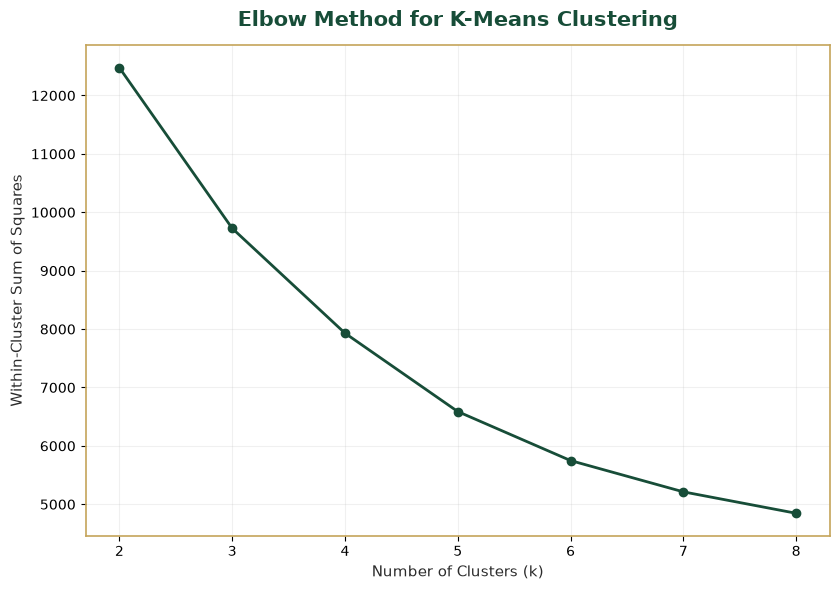

In [4]:
# Evaluate the number of clusters using the Elbow Method

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = range(2, 9)
inertia_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(clustering_scaled_df)

    inertia_values.append(
        model.inertia_
    )

fig, ax = plt.subplots(figsize=(8.5, 6))

ax.plot(
    list(k_values),
    inertia_values,
    marker="o",
    linewidth=2,
    color="#174D38"
)

ax.set_title(
    "Elbow Method for K-Means Clustering",
    fontsize=15,
    color="#174D38",
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Number of Clusters (k)",
    fontsize=11,
    color="#2B2B2B"
)

ax.set_ylabel(
    "Within-Cluster Sum of Squares",
    fontsize=11,
    color="#2B2B2B"
)

ax.grid(
    True,
    alpha=0.18
)

for spine in ax.spines.values():
    spine.set_edgecolor("#C5A45A")
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

In [5]:
# Run K-Means clustering with five clusters

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans.fit_predict(
    clustering_scaled_df
)

final_grid["cluster"] = cluster_labels + 1

print("Cluster counts:")
print(
    final_grid["cluster"]
    .value_counts()
    .sort_index()
)

Cluster counts:
cluster
1     449
2    2163
3    1085
4     207
5     796
Name: count, dtype: int64


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
4. Interpret Cluster Characteristics
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section compares the average characteristics of each cluster to understand how the groups differ in land surface temperature, vegetation, population, and building coverage. The cluster labels will be interpreted based on these observed profiles rather than their numeric IDs.
</p>

</div>

In [6]:
# Summarize the characteristics of each cluster

cluster_summary = (
    final_grid
    .groupby("cluster")[
        [
            "mean_lst_c",
            "mean_ndvi",
            "population",
            "building_coverage_pct"
        ]
    ]
    .mean()
    .round(2)
)

cluster_summary

,mean_lst_c,mean_ndvi,population,building_coverage_pct
cluster,,,,
1,53.69,0.04,999.64,34.65
2,50.50,0.08,2073.04,31.35
3,52.75,0.08,641.55,8.60
4,49.36,0.18,969.82,11.33
5,49.50,0.09,567.89,13.30


<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The five clusters represent distinct urban conditions across Riyadh. Cluster 1 contains the hottest and most heavily built-up cells, while Cluster 2 represents highly populated and relatively dense urban areas. Cluster 3 is also warm but is characterized by lower population and building coverage, suggesting more peripheral or exposed land. Cluster 4 has the highest vegetation levels and the lowest average surface temperature, while Cluster 5 represents cooler and generally lower-density areas. These profiles provide a basis for identifying which combinations of heat, vegetation, population, and built form may require greater greening priority.
</p>

</div>

In [7]:
# Assign descriptive names to the five clusters

cluster_names = {
    1: "Hot Dense Built-Up",
    2: "Dense Populated Urban",
    3: "Hot Low-Density Peripheral",
    4: "Greener Cooler Areas",
    5: "Cooler Lower-Density"
}

final_grid["cluster_name"] = final_grid["cluster"].map(
    cluster_names
)

print(
    final_grid[
        ["cluster", "cluster_name"]
    ]
    .drop_duplicates()
    .sort_values("cluster")
    .to_string(index=False)
)

 cluster               cluster_name
       1         Hot Dense Built-Up
       2      Dense Populated Urban
       3 Hot Low-Density Peripheral
       4       Greener Cooler Areas
       5       Cooler Lower-Density


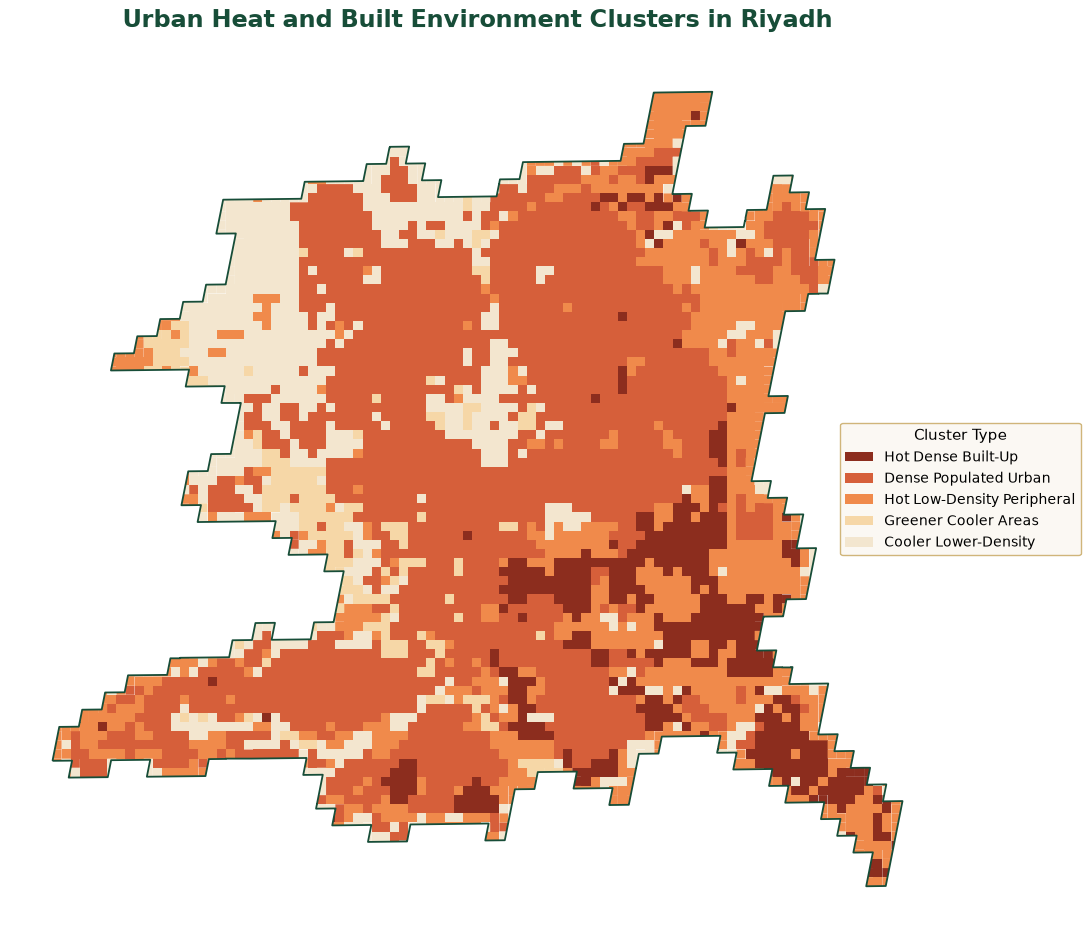

In [8]:
# Map the spatial distribution of K-Means clusters
# using a heat-oriented warm color palette

import matplotlib.pyplot as plt

cluster_colors = {
    "Hot Dense Built-Up": "#8C2D1E",          # darkest red
    "Dense Populated Urban": "#D65F3A",       # strong warm orange-red
    "Hot Low-Density Peripheral": "#F08A4B",  # orange
    "Greener Cooler Areas": "#F6D7A7",        # light warm sand
    "Cooler Lower-Density": "#F3E6CF"         # very light beige
}

fig, ax = plt.subplots(figsize=(11, 10))

for cluster_name, color in cluster_colors.items():
    subset = final_grid[
        final_grid["cluster_name"] == cluster_name
    ]

    subset.plot(
        ax=ax,
        color=color,
        edgecolor="none",
        label=cluster_name
    )

# Add Riyadh boundary outline
final_grid.dissolve().boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.3
)

ax.set_title(
    "Urban Heat and Built Environment Clusters in Riyadh",
    fontsize=17,
    color="#174D38",
    fontweight="bold",
    pad=18
)

legend = ax.legend(
    title="Cluster Type",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
    frameon=True,
    fontsize=10,
    title_fontsize=11
)

legend.get_frame().set_facecolor("#FAF7F0")
legend.get_frame().set_edgecolor("#C5A45A")
legend.get_frame().set_linewidth(1.0)

ax.set_axis_off()

fig.patch.set_facecolor("white")
ax.set_facecolor("#FAF7F0")

plt.tight_layout()
plt.show()

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The cluster map reveals distinct spatial patterns of urban heat, vegetation, population, and built form across Riyadh. The hottest and most densely built-up cluster is concentrated mainly in the eastern and southeastern parts of the study area, while cooler and greener conditions appear more frequently toward the western and southwestern areas. Highly populated urban cells occupy much of the central city. The warm color palette emphasizes differences in heat-related urban conditions across the five cluster types rather than representing a continuous temperature scale.
</p>

</div>

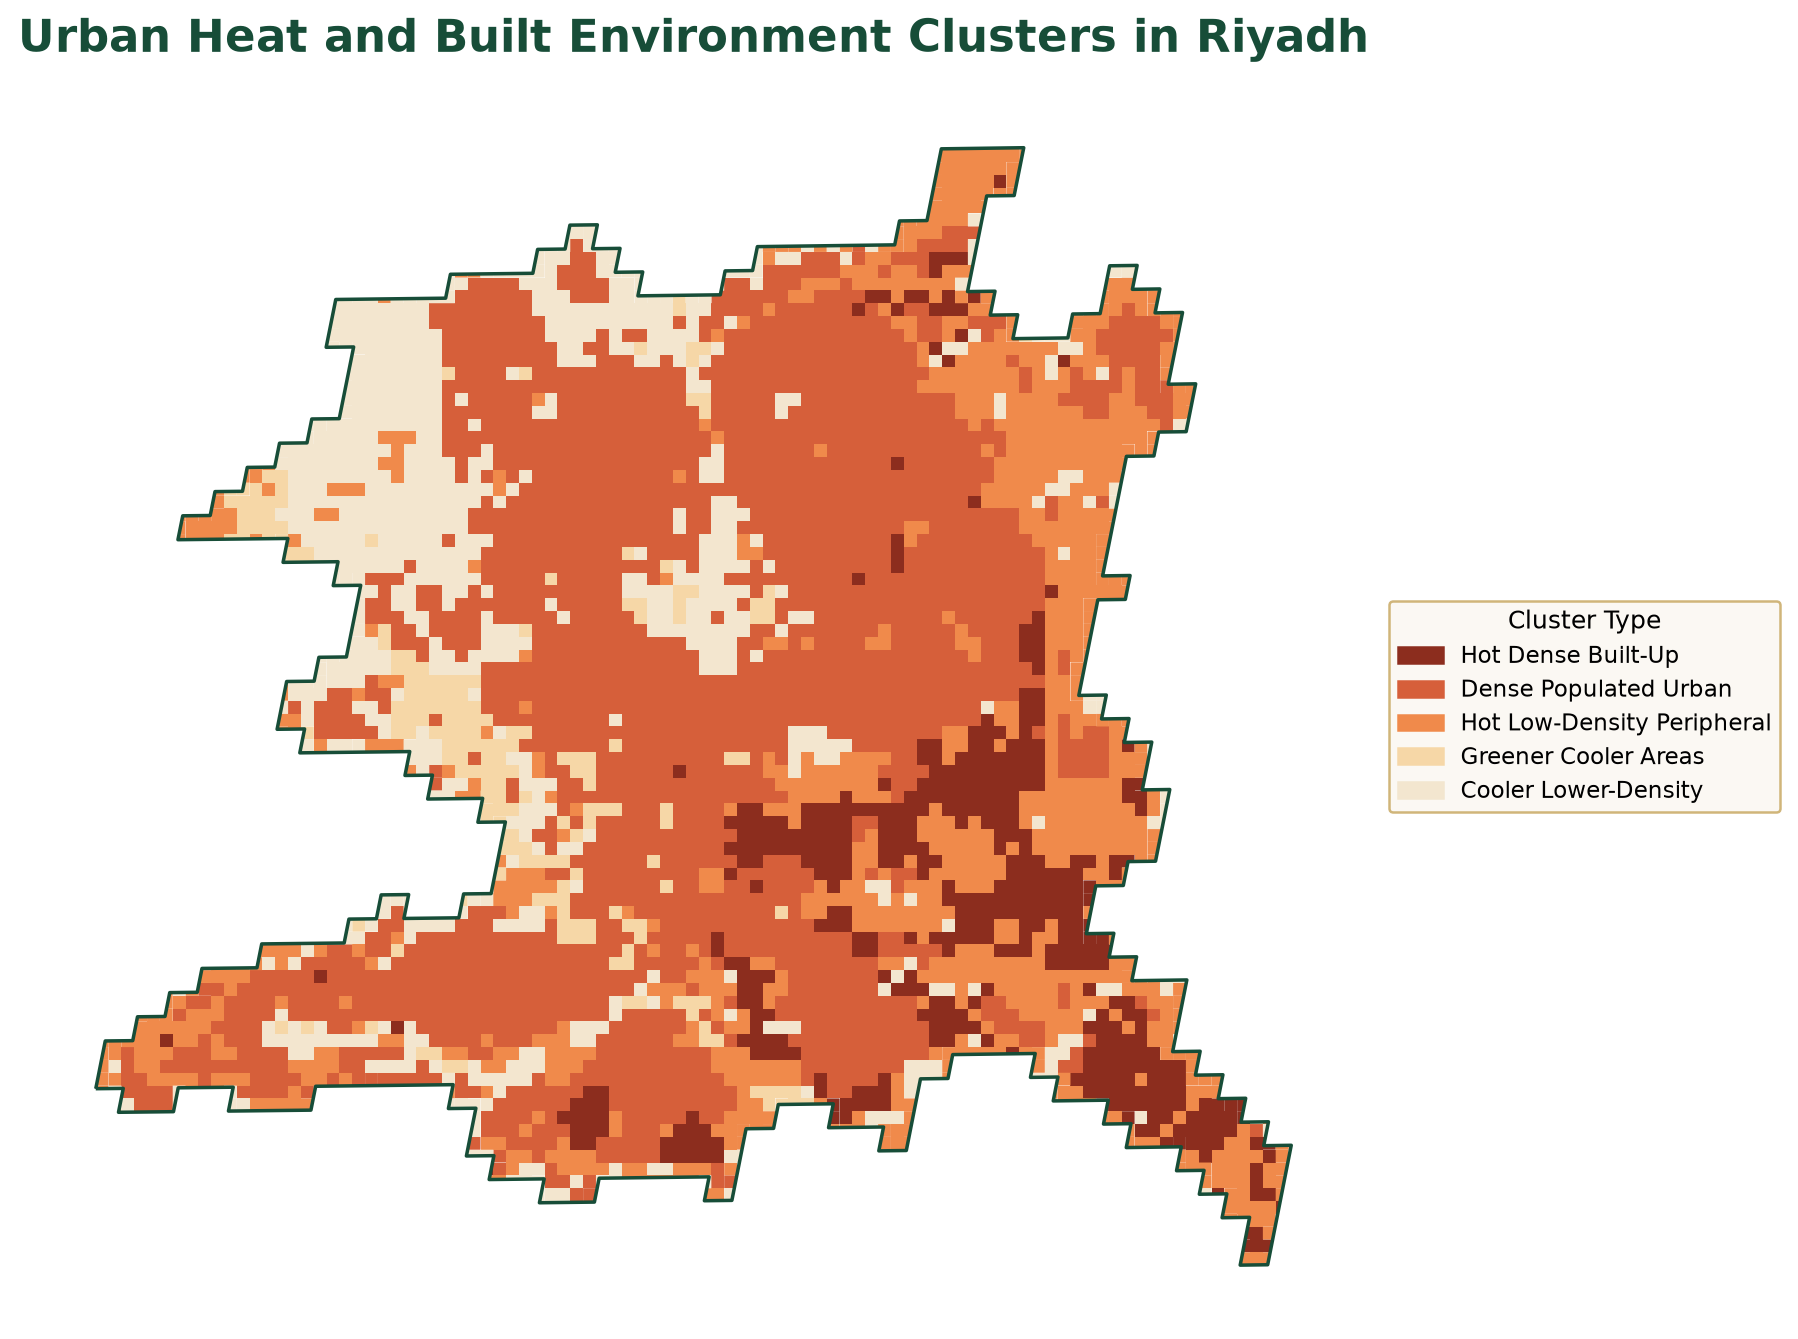

Cluster map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_AI_Clusters_Map.png


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import geopandas as gpd

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

cluster_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_AI_Clusters_Map.png"
)

cluster_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary_cluster = riyadh_boundary.to_crs(final_grid.crs)

# ---------------------------------------------------------
# Cluster labels
# ---------------------------------------------------------

cluster_names = {
    1: "Hot Dense Built-Up",
    2: "Dense Populated Urban",
    3: "Hot Low-Density Peripheral",
    4: "Greener Cooler Areas",
    5: "Cooler Lower-Density"
}

# ---------------------------------------------------------
# Cluster palette
# ---------------------------------------------------------

cluster_colors = {
    1: "#8C2D1E",
    2: "#D65F3A",
    3: "#F08A4B",
    4: "#F6D7A7",
    5: "#F3E6CF"
}

cluster_cmap = ListedColormap(
    [cluster_colors[i] for i in range(1, 6)]
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

final_grid.plot(
    column="cluster",
    cmap=cluster_cmap,
    categorical=True,
    linewidth=0,
    ax=ax
)

riyadh_boundary_cluster.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.4
)

# ---------------------------------------------------------
# Custom legend
# ---------------------------------------------------------

legend_handles = [
    mpatches.Patch(
        color=cluster_colors[i],
        label=cluster_names[i]
    )
    for i in range(1, 6)
]

ax.legend(
    handles=legend_handles,
    title="Cluster Type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor="#FAF7F0",
    edgecolor="#C5A45A",
    fontsize=9,
    title_fontsize=10
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "Urban Heat and Built Environment Clusters in Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#174D38",
    pad=16
)

ax.set_axis_off()

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    cluster_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Cluster map saved to:")
print(cluster_png_path)

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
5. Build the Spatial Priority Score
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section combines heat, vegetation, population exposure, and built-environment conditions into a spatial priority score. Higher priority will be assigned to grid cells that are hotter, less vegetated, more populated, and more heavily built-up.
</p>

</div>

In [9]:
# Normalize priority indicators to a common 0–1 scale

from sklearn.preprocessing import MinMaxScaler

priority_variables = [
    "mean_lst_c",
    "mean_ndvi",
    "population",
    "building_coverage_pct"
]

priority_scaler = MinMaxScaler()

priority_scaled = priority_scaler.fit_transform(
    final_grid[priority_variables]
)

priority_scaled_df = pd.DataFrame(
    priority_scaled,
    columns=[
        "heat_score",
        "vegetation_raw_score",
        "population_score",
        "building_score"
    ],
    index=final_grid.index
)

# Higher priority should represent lower vegetation,
# so the NDVI score is reversed
priority_scaled_df["low_vegetation_score"] = (
    1 - priority_scaled_df["vegetation_raw_score"]
)

# Add normalized indicators to the spatial dataset
final_grid["heat_score"] = priority_scaled_df["heat_score"]
final_grid["low_vegetation_score"] = priority_scaled_df["low_vegetation_score"]
final_grid["population_score"] = priority_scaled_df["population_score"]
final_grid["building_score"] = priority_scaled_df["building_score"]

print("Normalized priority indicators:")
print(
    final_grid[
        [
            "heat_score",
            "low_vegetation_score",
            "population_score",
            "building_score"
        ]
    ]
    .describe()
    .round(3)
)

Normalized priority indicators:
       heat_score  low_vegetation_score  population_score  building_score
count    4700.000              4700.000          4700.000        4700.000
mean        0.611                 0.762             0.451           0.322
std         0.107                 0.070             0.275           0.191
min         0.000                 0.000             0.000           0.000
25%         0.540                 0.746             0.203           0.165
50%         0.602                 0.775             0.482           0.339
75%         0.675                 0.794             0.694           0.468
max         1.000                 1.000             1.000           1.000


In [10]:
# Calculate the spatial priority score using weighted indicators

final_grid["priority_score"] = (
    0.35 * final_grid["heat_score"]
    + 0.30 * final_grid["low_vegetation_score"]
    + 0.25 * final_grid["population_score"]
    + 0.10 * final_grid["building_score"]
)

print("Priority score summary:")
print(
    final_grid["priority_score"]
    .describe()
    .round(3)
)

Priority score summary:
count    4700.000
mean        0.587
std         0.093
min         0.098
25%         0.521
50%         0.607
75%         0.660
max         0.815
Name: priority_score, dtype: float64


In [11]:
# Classify the spatial priority score into five priority levels

priority_labels = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High"
]

final_grid["priority_level"] = pd.qcut(
    final_grid["priority_score"],
    q=5,
    labels=priority_labels
)

print("Priority level counts:")
print(
    final_grid["priority_level"]
    .value_counts()
    .reindex(priority_labels)
)

print()
print("Priority score ranges:")
print(
    final_grid
    .groupby("priority_level", observed=True)["priority_score"]
    .agg(["min", "max"])
    .round(3)
)

Priority level counts:
priority_level
Very Low     940
Low          940
Moderate     940
High         940
Very High    940
Name: count, dtype: int64

Priority score ranges:
                  min    max
priority_level              
Very Low        0.098  0.499
Low             0.499  0.579
Moderate        0.580  0.631
High            0.631  0.668
Very High       0.668  0.815


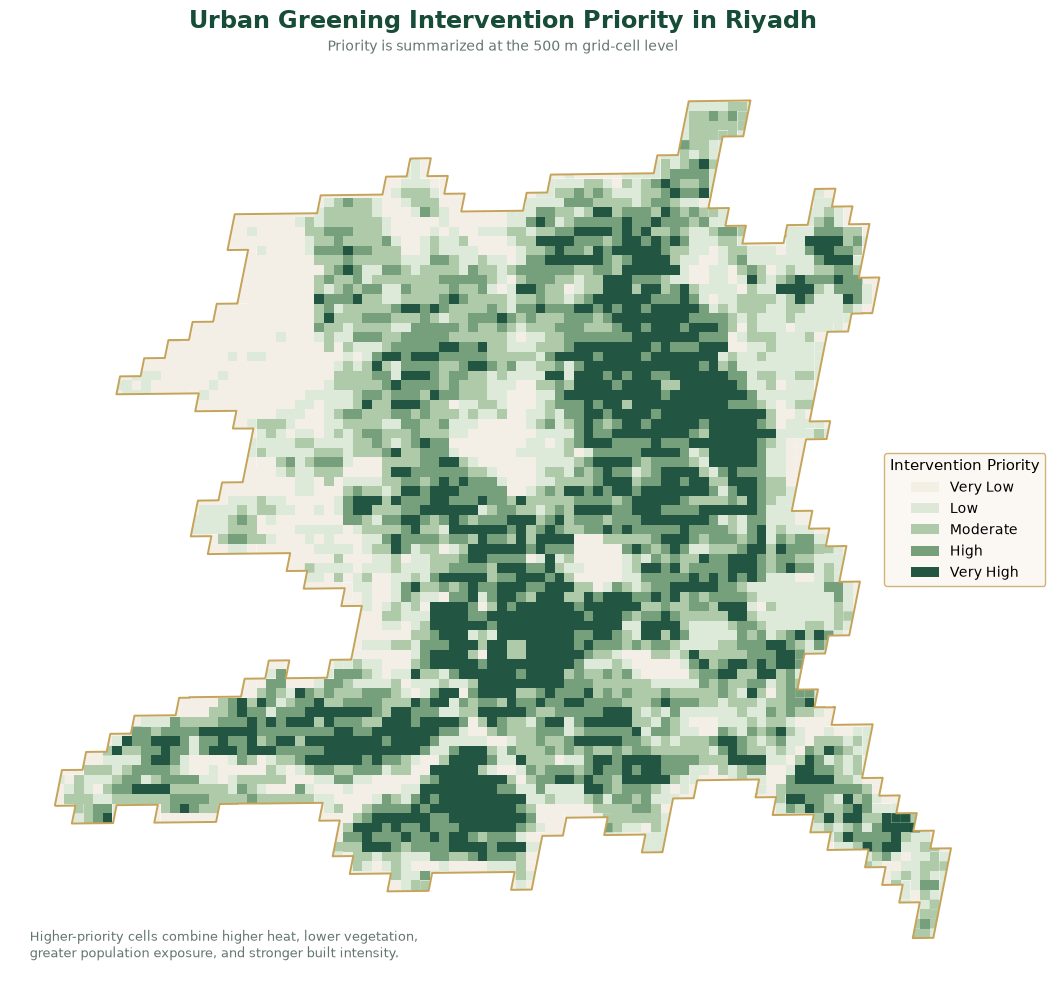

In [12]:
# Map urban greening intervention priority using calm 500 m grid cells

import matplotlib.pyplot as plt

priority_colors = {
    "Very Low": "#F4EFE5",
    "Low": "#DCE8D7",
    "Moderate": "#ABC8A4",
    "High": "#6F9A74",
    "Very High": "#174D38"
}

# keep the plotting order fixed
priority_order = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High"
]

fig, ax = plt.subplots(figsize=(11, 10))

for priority_level in priority_order:
    color = priority_colors[priority_level]

    subset = final_grid[
        final_grid["priority_level"] == priority_level
    ]

    subset.plot(
        ax=ax,
        color=color,
        edgecolor="none",
        alpha=0.95,
        label=priority_level
    )

# Add Riyadh boundary
final_grid.dissolve().boundary.plot(
    ax=ax,
    color="#C5A45A",
    linewidth=1.4
)

ax.set_title(
    "Urban Greening Intervention Priority in Riyadh",
    fontsize=17,
    color="#174D38",
    fontweight="bold",
    pad=22
)

ax.text(
    0.5,
    1.005,
    "Priority is summarized at the 500 m grid-cell level",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="#65766D"
)

legend = ax.legend(
    title="Intervention Priority",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
    frameon=True,
    fontsize=10,
    title_fontsize=11
)

legend.get_frame().set_facecolor("#FAF7F0")
legend.get_frame().set_edgecolor("#C5A45A")
legend.get_frame().set_linewidth(1.0)

ax.text(
    0.02,
    0.02,
    "Higher-priority cells combine higher heat, lower vegetation,\ngreater population exposure, and stronger built intensity.",
    transform=ax.transAxes,
    fontsize=9,
    color="#65766D",
    va="bottom"
)

ax.set_axis_off()

fig.patch.set_facecolor("white")
ax.set_facecolor("#FAF7F0")

plt.tight_layout()
plt.show()

<div style="background:#FAF7F0; padding:12px 16px; border-left:5px solid #C5A45A; border-radius:8px; margin:12px 0;">

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
The priority map identifies 500 m grid cells where high land surface temperature, low vegetation, population exposure, and built-environment intensity overlap most strongly. Darker green cells represent higher relative priority for further greening evaluation, while lighter cells indicate lower priority. These results support spatial screening and should be interpreted as areas for further assessment rather than direct planting recommendations.
</p>

</div>

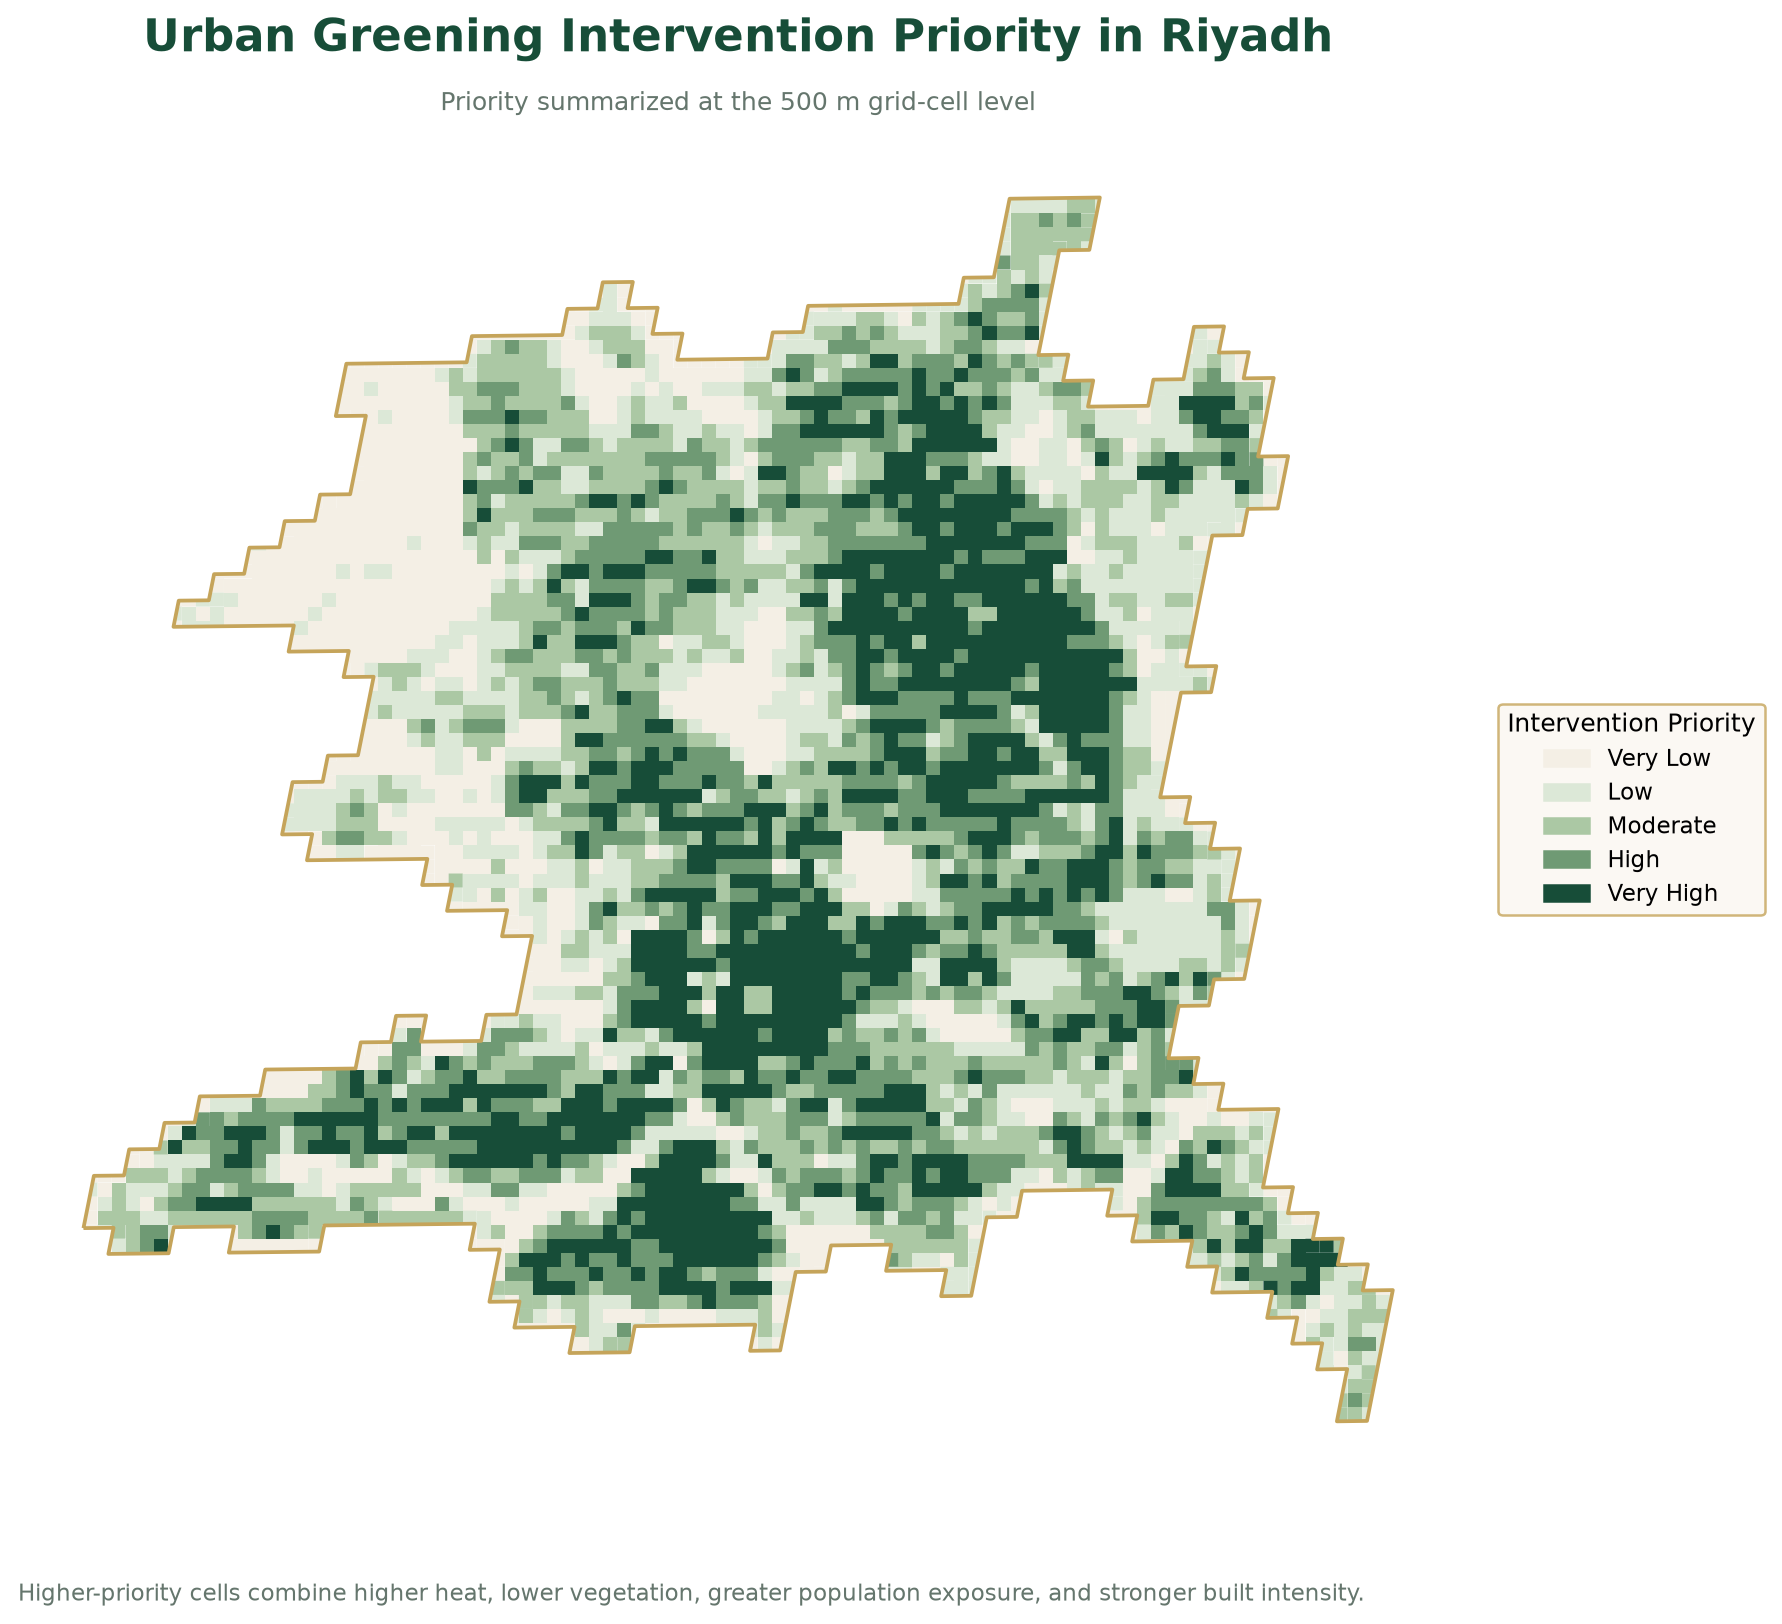

Greening priority map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_Greening_Priority_Map.png


In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

priority_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_Greening_Priority_Map.png"
)

priority_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary_priority = riyadh_boundary.to_crs(final_grid.crs)

# ---------------------------------------------------------
# Priority order and colors
# ---------------------------------------------------------

priority_order = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High"
]

priority_colors = {
    "Very Low": "#F4EFE5",
    "Low": "#DCE8D7",
    "Moderate": "#ABC8A4",
    "High": "#6F9A74",
    "Very High": "#174D38"
}

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

for level in priority_order:
    subset = final_grid[
        final_grid["priority_level"] == level
    ]

    subset.plot(
        ax=ax,
        color=priority_colors[level],
        linewidth=0
    )

# Riyadh boundary
riyadh_boundary_priority.boundary.plot(
    ax=ax,
    color="#C5A45A",
    linewidth=1.5
)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

legend_handles = [
    mpatches.Patch(
        color=priority_colors[level],
        label=level
    )
    for level in priority_order
]

ax.legend(
    handles=legend_handles,
    title="Intervention Priority",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor="#FAF7F0",
    edgecolor="#C5A45A",
    fontsize=9,
    title_fontsize=10
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "Urban Greening Intervention Priority in Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#174D38",
    pad=34
)

ax.text(
    0.5,
    1.015,
    "Priority summarized at the 500 m grid-cell level",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="#65766D"
)

ax.text(
    0.0,
    -0.075,
    (
        "Higher-priority cells combine higher heat, lower vegetation, "
        "greater population exposure, and stronger built intensity."
    ),
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color="#65766D"
)

ax.set_axis_off()

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    priority_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Greening priority map saved to:")
print(priority_png_path)

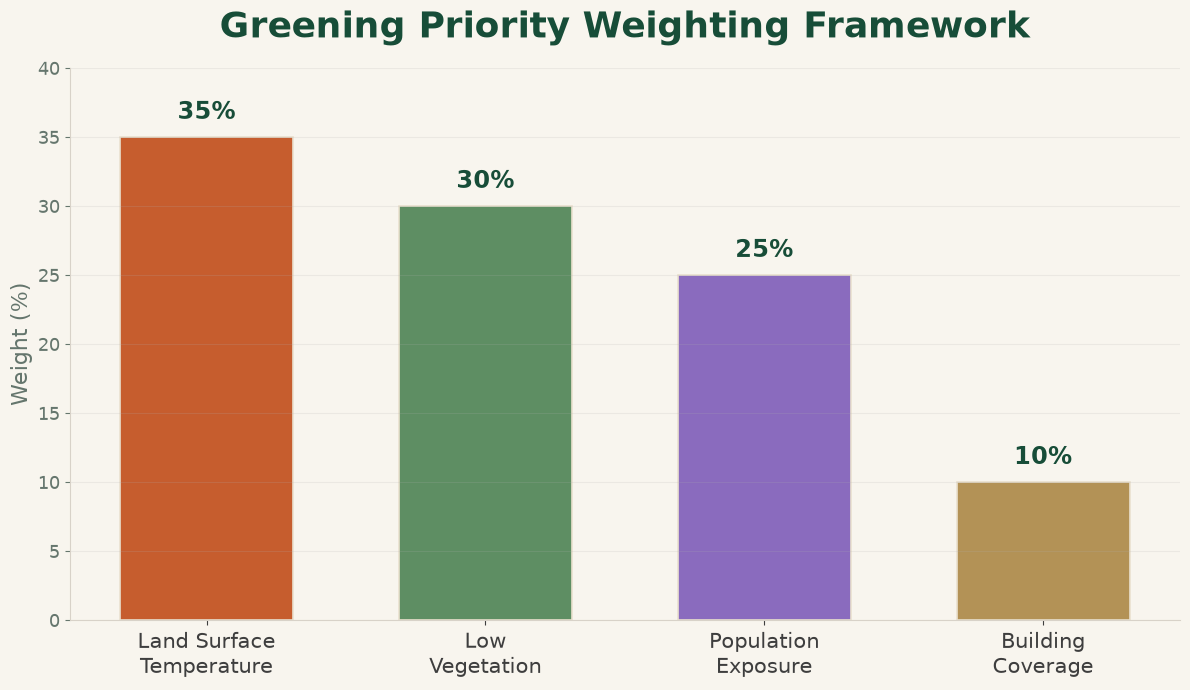

Priority weights chart saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_Priority_Weights_Chart.png


In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# Project path
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

# ---------------------------------------------------------
# Priority weights
# ---------------------------------------------------------

factors = [
    "Land Surface\nTemperature",
    "Low\nVegetation",
    "Population\nExposure",
    "Building\nCoverage"
]

weights = [35, 30, 25, 10]

# ألوان مرتبطة بهوية كل متغير
colors = [
    "#C65D2E",  # LST - orange/red
    "#5E8E63",  # Low Vegetation - green
    "#8A6BBE",  # Population - purple
    "#B39256"   # Building Coverage - gold/brown
]

# ---------------------------------------------------------
# Output path
# ---------------------------------------------------------

weights_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_Priority_Weights_Chart.png"
)

weights_png_path.parent.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.bar(
    factors,
    weights,
    color=colors,
    width=0.62,
    edgecolor="#EAE1CF",
    linewidth=1.2
)

# Title
ax.set_title(
    "Greening Priority Weighting Framework",
    fontsize=26,
    fontweight="bold",
    color="#174D38",
    pad=22
)

# Y-axis
ax.set_ylabel(
    "Weight (%)",
    fontsize=16,
    color="#65766D"
)

ax.set_ylim(0, 40)
ax.set_yticks(np.arange(0, 41, 5))
ax.tick_params(axis="y", labelsize=13, colors="#65766D")

# X-axis
ax.tick_params(axis="x", labelsize=15, colors="#3E3E3E")

# Grid
ax.grid(axis="y", linestyle="-", alpha=0.18)

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#D8D2C8")
ax.spines["bottom"].set_color("#D8D2C8")

# Value labels
for bar, value in zip(bars, weights):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.9,
        f"{value}%",
        ha="center",
        va="bottom",
        fontsize=17,
        fontweight="bold",
        color="#174D38"
    )

# Background
fig.patch.set_facecolor("#F8F5EE")
ax.set_facecolor("#F8F5EE")

plt.tight_layout()

# Save
plt.savefig(
    weights_png_path,
    dpi=220,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Priority weights chart saved to:")
print(weights_png_path)

<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #174D38; border-radius:8px; margin:14px 0;">

<h2 style="color:#174D38; margin:0 0 6px 0;">
6. Export Final Priority Dataset and Summary
</h2>

<p style="color:#2B2B2B; margin:0; line-height:1.6;">
This section exports the final spatial dataset containing cluster assignments, priority indicators, and greening intervention scores. The outputs will support the final maps, website, report, and presentation.
</p>

</div>

In [13]:
# Export the final clustering and greening priority dataset

final_priority_output = (
    project_root
    / "outputs"
    / "Riyadh_500m_Clustering_and_Greening_Priority.gpkg"
)

final_grid.to_file(
    final_priority_output,
    driver="GPKG"
)

print("Saved final priority dataset to:")
print(final_priority_output)

Saved final priority dataset to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\Riyadh_500m_Clustering_and_Greening_Priority.gpkg


In [14]:
# Export the final clustering and greening priority table as CSV

final_priority_csv = (
    project_root
    / "outputs"
    / "Riyadh_500m_Clustering_and_Greening_Priority.csv"
)

final_grid.drop(
    columns="geometry"
).to_csv(
    final_priority_csv,
    index=False
)

print("Saved final priority table to:")
print(final_priority_csv)

Saved final priority table to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\outputs\Riyadh_500m_Clustering_and_Greening_Priority.csv


<div style="background:#FAF7F0; padding:14px 18px; border-left:6px solid #C5A45A; border-radius:8px; margin:14px 0;">

<h3 style="color:#174D38; margin:0 0 8px 0;">
Notebook Summary
</h3>

<p style="color:#2B2B2B; margin:0; line-height:1.7;">
This notebook applied K-Means clustering and spatial prioritization to the 500 m Riyadh analysis grid prepared in Notebook 01. Five urban clusters were identified based on land surface temperature, vegetation, population, and building coverage. A weighted greening priority score was then calculated using heat, low vegetation, population exposure, and built-environment intensity. The final outputs identify areas that may warrant further greening evaluation, while recognizing that detailed site suitability would require additional information such as land ownership, irrigation access, infrastructure constraints, and local design conditions.
</p>

</div>